# Playground Series S6E9 — EDA
Target: `Will_Buy_EV` (binary classification)

Key Takeaways (fill in after running):
- ...


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")
print(train.shape, test.shape)
train.head()


(668665, 15) (286571, 14)


,id,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level,Gender,City_Type,Current_Car_Type,Home_Charging_Possible,Subsidy_Available,Range_Anxiety_Level,Will_Buy_EV
0,0,66,92887.0,23.4,2,3,7,1.0,Male,Suburban,Sedan,Yes,No,Low,No
1,1,38,30000.0,5.0,1,2,2,4.0,Male,Rural,SUV,Yes,No,Low,No
2,2,26,94389.0,36.8,1,8,15,5.0,Female,Urban,Sedan,No,Yes,Low,Yes
3,3,66,73580.0,23.7,2,6,9,3.0,Male,Suburban,Hatchback,Yes,No,Low,No
4,4,54,57898.0,50.8,1,2,3,3.0,Male,Suburban,Hatchback,Yes,No,Low,No


## Target encoding
Target is `Yes`/`No` — encode to `Will_Buy_EV_bin` (1/0) for stats & modeling.

In [2]:
train["Will_Buy_EV_bin"] = (train["Will_Buy_EV"] == "Yes").astype(int)
train["Will_Buy_EV_bin"].value_counts(normalize=True)


Will_Buy_EV_bin
0    0.825355
1    0.174645
Name: proportion, dtype: float64

## Schema & missingness

In [3]:
train.info()
print("\nMissing values (train):")
print(train.isna().sum())


<class 'pandas.DataFrame'>
RangeIndex: 668665 entries, 0 to 668664
Data columns (total 16 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   id                           668665 non-null  int64  
 1   Age                          668665 non-null  int64  
 2   Annual_Income_USD            668665 non-null  float64
 3   Daily_Commute_km             668665 non-null  float64
 4   Number_of_Cars_Owned         668665 non-null  int64  
 5   Charging_Stations_Near_Home  668665 non-null  int64  
 6   Charging_Stations_Near_Work  668665 non-null  int64  
 7   Environmental_Concern_Level  668665 non-null  float64
 8   Gender                       668665 non-null  str    
 9   City_Type                    668665 non-null  str    
 10  Current_Car_Type             668665 non-null  str    
 11  Home_Charging_Possible       668665 non-null  str    
 12  Subsidy_Available            668665 non-null  str    
 13  Range_Anxi

id                             0
Age                            0
Annual_Income_USD              0
Daily_Commute_km               0
Number_of_Cars_Owned           0
Charging_Stations_Near_Home    0
Charging_Stations_Near_Work    0
Environmental_Concern_Level    0
Gender                         0
City_Type                      0
Current_Car_Type               0
Home_Charging_Possible         0
Subsidy_Available              0
Range_Anxiety_Level            0
Will_Buy_EV                    0
Will_Buy_EV_bin                0
dtype: int64


## Target balance

Will_Buy_EV_bin
0    0.825355
1    0.174645
Name: proportion, dtype: float64


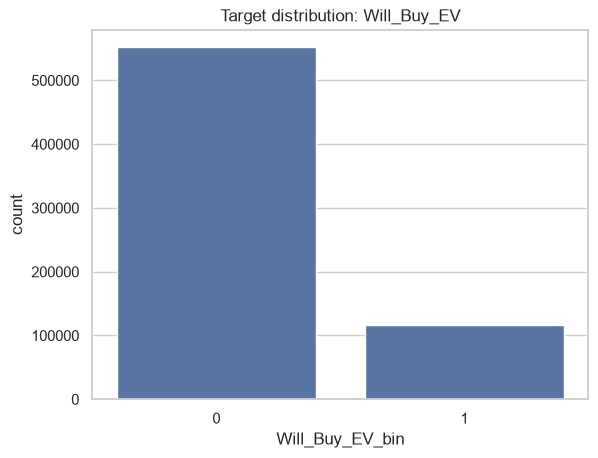

In [4]:
target = "Will_Buy_EV_bin"
print(train[target].value_counts(normalize=True))
sns.countplot(x=target, data=train)
plt.title("Target distribution: Will_Buy_EV")
plt.show()


## Numeric feature distributions

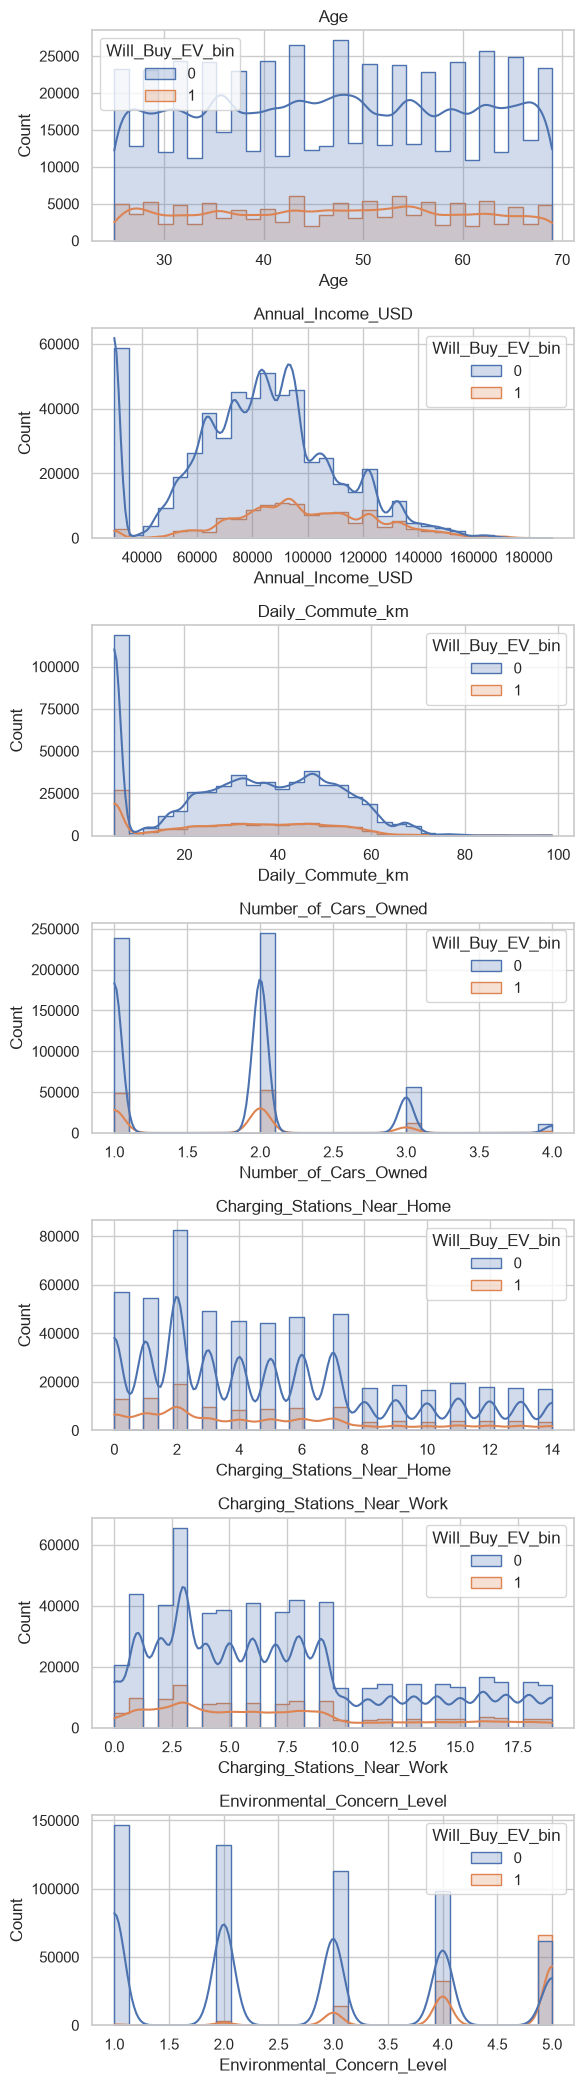

In [5]:
numeric_cols = train.select_dtypes(include=[np.number]).columns.drop(["id", "Will_Buy_EV_bin"], errors="ignore")
fig, axes = plt.subplots(len(numeric_cols), 1, figsize=(6, 3 * len(numeric_cols)))
for ax, col in zip(axes, numeric_cols):
    sns.histplot(data=train, x=col, hue=target, bins=30, kde=True, ax=ax, element="step")
    ax.set_title(col)
plt.tight_layout()
plt.show()


## Categorical feature vs target

In [6]:
cat_cols = train.select_dtypes(exclude=[np.number]).columns.drop(["Will_Buy_EV"], errors="ignore")
for col in cat_cols:
    rate = train.groupby(col)[target].mean().sort_values(ascending=False)
    print(f"\n--- {col} ---")
    print(rate)



--- Gender ---
Gender
Female    0.177641
Other     0.173732
Male      0.172253
Name: Will_Buy_EV_bin, dtype: float64

--- City_Type ---
City_Type
Rural       0.193389
Suburban    0.180936
Urban       0.161058
Name: Will_Buy_EV_bin, dtype: float64

--- Current_Car_Type ---
Current_Car_Type
SUV          0.180953
Hatchback    0.174299
Sedan        0.171967
Truck        0.156413
Name: Will_Buy_EV_bin, dtype: float64

--- Home_Charging_Possible ---
Home_Charging_Possible
Yes    0.195819
No     0.127085
Name: Will_Buy_EV_bin, dtype: float64

--- Subsidy_Available ---
Subsidy_Available
Yes    0.274695
No     0.005757
Name: Will_Buy_EV_bin, dtype: float64

--- Range_Anxiety_Level ---
Range_Anxiety_Level
Low       0.189027
Medium    0.041745
High      0.001367
Name: Will_Buy_EV_bin, dtype: float64


## Correlation of numeric features with target

Environmental_Concern_Level    0.464079
Annual_Income_USD              0.225729
Daily_Commute_km              -0.045866
Charging_Stations_Near_Home   -0.016353
Charging_Stations_Near_Work   -0.012229
Age                           -0.007450
Number_of_Cars_Owned           0.003896
Name: Will_Buy_EV_bin, dtype: float64


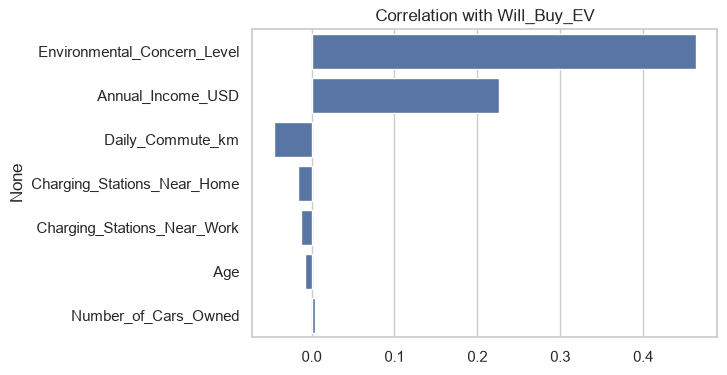

In [7]:
corr = train[list(numeric_cols) + [target]].corr()[target].drop(target).sort_values(key=abs, ascending=False)
print(corr)
plt.figure(figsize=(6, 4))
sns.barplot(x=corr.values, y=corr.index, orient="h")
plt.title("Correlation with Will_Buy_EV")
plt.show()


## Key Takeaways

- Target balance: see cell above — note class imbalance ratio for stratified CV / class weighting choice.
- Strongest numeric correlates with purchase intent: see correlation bar chart.
- Categorical features with clear purchase-rate separation are candidates for target/frequency encoding in `02_feature_engineering.ipynb`.
